# PCHN63112 Workshop 2: Logistic Regression
In this week's lesson, we introduced ...

## Understanding the Logit Transform
...

### Understanding Odds
... Odds are helpful because we can combine risks together in a way that we can't for probability. For instance, if we had a baseline risk ... We cannot simply add these probabilities together because we may get a value greater than 1. Similarly, we cannot multiply them because the value will always get smaller, breaking the logic of trying to combine multiple risks together. 

Instead, we can transform probabilities into odds, combine them, and then transform them back to probabilities. 

... We cannot simply add odds together because this creates an answer that does not make sense. For instance if the odds are doubled for one risk factor and halved for another, then the overall risk should simply be 1 because the risks cancel. This doesn't work when you add the odds

$$
    2.0 + 0.5 = 2.5,
$$

but it does when you multiply them

$$
    2.0 \times 0.5 = 1.0.
$$

As such, odds are *multiplicative*. 

### The Limitations of Odds
... The fact that odds are *multiplicative* is also an issue, because linear regression is *additive*. We do not multiply the variables together, we add them.

### What the Log-Odds Gives Us

<div class="alert alert-block alert-success"><b>Exercise #</b> 

Try ...
</div>

## Understanding the Different Scales
Perhaps the trickiest aspect of logistic regression, as you hopefully now appreciate, is that there are actually *three* scales that we can work on: the *log-odds*, the *odds* and *probability*. 

What is important to remember is that only the *log-odds* are linear. The odds are *exponential* (because we calculate $e^{\beta_{0} + \beta_{1}x}$ ) and probability is *S-shaped*. This is illustrated in the graphs below. On the left ... In the middle ... Notice that the odds ratio remains the same at the two highlighted points, but that the difference in the odds is larger at higher values of age, due to the shape of the curve. On the right ... Notice that the same odds ratios result in different changes in the probability.  

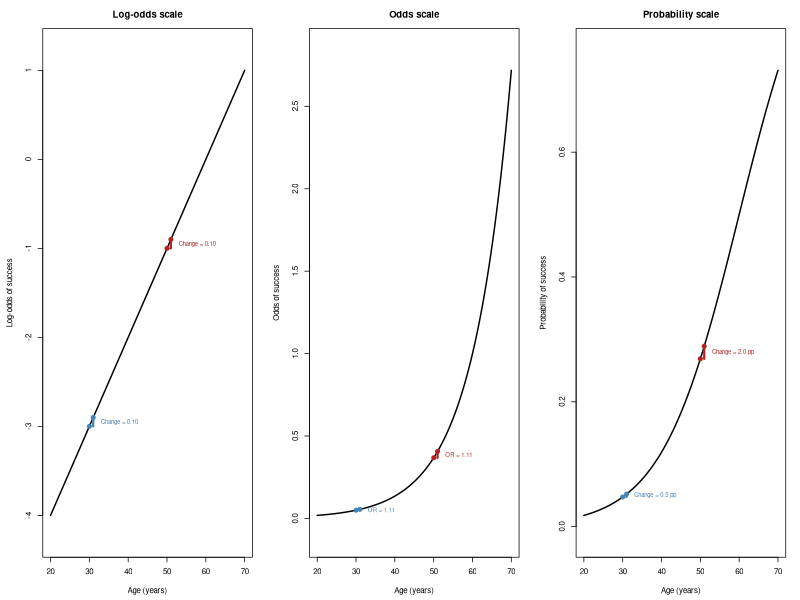

In [ ]:

# Model parameters
beta0 <- -6
beta1 <- 0.10

# Ages to compare
ages <- c(30, 50)
delta <- 1

# Model functions
log_odds <- function(age) {
  beta0 + beta1 * age
}

odds <- function(age) {
  exp(log_odds(age))
}

prob <- function(age) {
  plogis(log_odds(age))
}

# Values for plotting
x <- seq(20, 70, length.out = 500)

# Colours
cols <- c("steelblue", "firebrick")

# Three panels
par(mfrow = c(1, 3), mar = c(4.5, 4.5, 3, 1.5))

for (scale in c("log-odds", "odds", "probability")) {

  if (scale == "log-odds") {
    f <- log_odds
    ylab <- "Log-odds of success"
    main <- "Log-odds scale"
  } else if (scale == "odds") {
    f <- odds
    ylab <- "Odds of success"
    main <- "Odds scale"
  } else {
    f <- prob
    ylab <- "Probability of success"
    main <- "Probability scale"
  }

  # Plot fitted relationship
  yrange <- range(f(x))
  ylim <- yrange + c(-1, 1) * diff(yrange) * 0.05

  plot(x, f(x),
       type = "l", lwd = 2,
       xlab = "Age (years)", ylab = ylab,
       main = main, ylim = ylim)

  for (i in seq_along(ages)) {

    age1 <- ages[i]
    age2 <- age1 + delta

    y1 <- f(age1)
    y2 <- f(age2)

    # Highlight the two predicted values
    points(c(age1, age2), c(y1, y2),
           pch = 19, col = cols[i], cex = 1.2)

    # Vertical difference
    segments(age2, y1, age2, y2,
             col = cols[i], lwd = 3)

    # Horizontal reference
    segments(age1, y1, age2, y1,
             col = cols[i], lty = 2)

    # Labels appropriate to each scale
    label <- switch(scale,
      "log-odds" = sprintf("Change = %.2f", y2 - y1),
      "odds" = sprintf("OR = %.2f", y2 / y1),
      "probability" = sprintf(
        "Change = %.1f pp", 100 * (y2 - y1))
    )

    text(age2 + 2, (y1 + y2) / 2,
         labels = label, col = cols[i],
         adj = 0, cex = 0.75)
  }
}

par(mfrow = c(1, 1))


An important property of exponential functions is that they turn an additive relationship into a multiplicative one. A basic rule is that

$$
e^{a + b} = e^{a} \times e^{b}.
$$

Applying this to simple logistic regression with $x = 1$ gives

$$
e^{\beta_{0} + \beta_{1}} = e^{\beta_{0}} \times e^{\beta_{1}} = \text{odds}_{x=0} \times \text{OR}_{x+1}.
$$

So, the baseline odds are *multiplied* by the odds ratio. This means that the absolute value of the odds will increase exponentially by being multiplied at each step by the same value. As an example, consider the table below.

| $x$ |	Log-odds	| Odds  | Change in odds |
| --- | ----------- | ----- | -------------- |
| 0   |	0.0         | 1.000 | (baseline)     |
| 1   | 0.5	        | 1.649 | $\times 1.649$ |
| 2	  | 1.0	        | 2.718 | $\times 1.649$ |
| 3	  | 1.5	        | 4.482 | $\times 1.649$ |

Notice that the log-odds increase by the same amount each time. They are *additive*. However, notice that the odds do not increase by the same amount each time, but they do get *scaled* by the same amount each time. They are *multiplicative*.

## Interactions

Loading required package: carData
lattice theme set by effectsTheme()
See ?effectsTheme for details.


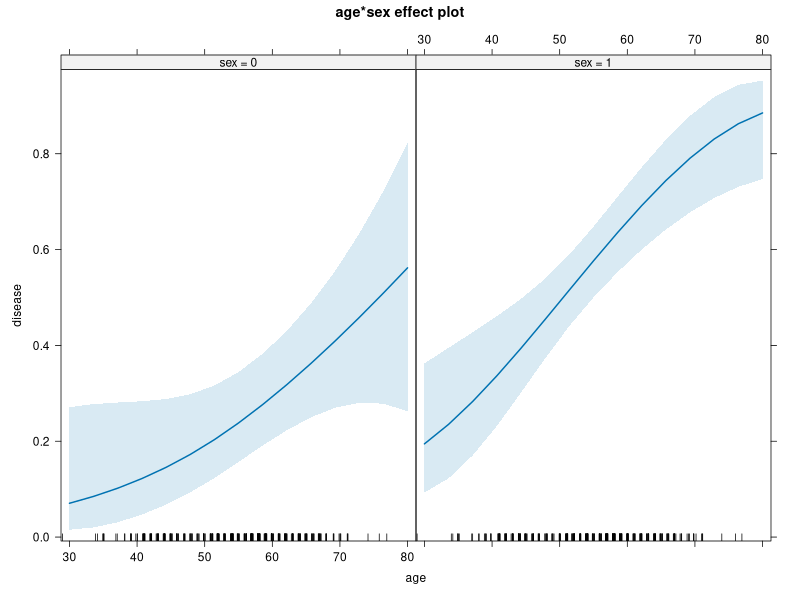

In [2]:
library('datarium')
library('effects')

data('heartdisease')

cleveland         <- subset(heartdisease, dataset == "cleveland")
cleveland$disease <- as.integer(cleveland$num > 0)
cleveland$sex     <- as.factor(cleveland$sex)

mod <- glm(disease ~ age * sex, family=binomial(link=logit), data=cleveland)
plot(allEffects(mod), axes=list(y=list(type="response")))